In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import fastplotlib as fpl
import tifffile
from skophys.viz_helpers import spatial_to_rgba
from tifffile.tifffile import imwrite
from scipy.optimize import curve_fit
import pickle

from skophys.preprocessing import UnVectorizer, Vectorizer
from skophys.datasets import ARProcess, ARProcessMovie

import jax
import jax.numpy as jnp

%matplotlib inline

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),Apple M2,IntegratedGPU,Metal,


/Users/rshang/miniforge3/envs/jax-arm/lib/python3.11/site-packages/numba-0.61.2-py3.11-macosx-11.1-arm64.egg/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
output_dir = "/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/"

filepath = []
file_label = []


# n_sources = 2
# list_time_correlation = []
# list_time_correlation += [0.]
# list_time_correlation += [0.1]
# # list_time_correlation += [0.2]
# # list_time_correlation += [0.3]
# # list_time_correlation += [0.4]
# # list_time_correlation += [0.5]
# # list_time_correlation += [0.6]
# # list_time_correlation += [0.7]
# # list_time_correlation += [0.8]
# list_source_separation = []
# list_source_separation += [1]
# list_source_separation += [2]
# # list_source_separation += [3]
# # list_source_separation += [4]
# # list_source_separation += [5]
# # list_source_separation += [6]
# # list_source_separation += [7]
# # list_source_separation += [8]
# # list_source_separation += [9]
# for source_separation in list_source_separation:
#     for time_correlation  in list_time_correlation:
#         file_label += [f"ToySim_s{source_separation}_t{int(time_correlation*10)}"]
#         filepath += [f'/Users/rshang/Work/fermipy/make_movie_array/data/ToySim_{file_label[-1]}.pkl']

# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"]
# file_label += ["Calcium"]
filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif"]
file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/sue2p.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/1p.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/vaz_crop_2.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/vaz_crop_1.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/885D5_MC_rect-0_n-clusters-10.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/885D5_MC_rect-3_n-clusters-19.tif"]
# file_label += ["Calcium"]
# filepath += ["/Users/rshang/Work/caiman/mesmerize-core/exp_data/M19D5_MC_rect-1_n-clusters-19.tif"]
# file_label += ["Calcium"]


# file_label += ["Fermi_movie_l100_b0"]
# file_label += ["Fermi_movie_l105_b0"]
# file_label += ["Fermi_movie_l110_b0"]
# file_label += ["Fermi_movie_l90_b0"]
# file_label += ["Fermi_movie_l95_b0"]
# for fl in file_label:
#     filepath += [f"/Users/rshang/Work/fermipy/make_movie_array/data/{fl}.pkl"]

In [3]:
ana_label = ""

# ana_label += "_noncentered"
# use_centering = 0 # no centering
# ana_label += "_precentered"
# use_centering = 1 # only center whitening matrix
# ana_label += "_fullcentered"
# use_centering = 2 # center both whitening matrix and data
ana_label += "_filtercentered"
use_centering = 3 # center both whitening matrix and data

fixed_n_components = 0 # zero is default

bkg_sigma = 0.
# bkg_sigma = 1.
# bkg_sigma = -1. # loose cut

n_time_windows = 1

# analysis_type = 0 # similarity matching
analysis_type = 1 # covariance matching
# analysis_type = 2 # hybrid matching

use_covariance_weights = True
# use_covariance_weights = False

ana_label += "_whiten"
use_whitening = True
# ana_label += "_nonwhiten"
# use_whitening = False

ana_label += "_truncated"
truncate_spectrum = True
# ana_label += "_nontruncated"
# truncate_spectrum = False

# use_eco_init = True
use_eco_init = False

n_lags = 0
# n_lags = 1
# n_lags = 2
ana_label += f"_{n_lags}lag"


lag_time = 1

In [4]:
def read_sim_data_file(path):

    with open(path, 'rb') as f:
        data_loaded = pickle.load(f)
        movie = data_loaded['histogram']
        N_movie = data_loaded['noise_histogram']
        traces_truth = data_loaded['traces_truth']
        source_footprints = data_loaded['source_footprints']

    return movie, N_movie, traces_truth, source_footprints

def read_fermi_data_file(path):
    
    with open(path, 'rb') as f:
        data_loaded = pickle.load(f)
        energy_edges = data_loaded['energy_edges']
        time_intervals = data_loaded['time_intervals']
        mjd_intervals = data_loaded['mjd_intervals']
        pix_coord = data_loaded['pix_coord']
        sky_coord = data_loaded['sky_coord']
        pix_x_coord = pix_coord[1]
        pix_y_coord = pix_coord[0]
        sky_x_coord = sky_coord[1]
        sky_y_coord = sky_coord[0]

        n_energy_bins = len(energy_edges)-1

        # movie = data_loaded['noise_histogram']
        movie = data_loaded['histogram']
        N_movie = data_loaded['noise_histogram']
            
        # edges = data_loaded['edges']

    n_time_windows = n_energy_bins
    
    return movie, N_movie, pix_x_coord, pix_y_coord, sky_x_coord, sky_y_coord, time_intervals, mjd_intervals

def read_data_file(path):

    movie = tifffile.imread(path)[:]

    target_pix_dim = 15
    target_time_dim = min(2000, movie.shape[0])
    image_center_pix_x = int(movie.shape[1]/2)
    image_center_pix_y = int(movie.shape[2]/2)

    # movie = movie[:target_time_dim, :, :]
    movie = movie[:target_time_dim, ::2, ::2]
    # movie = movie[:target_time_dim, image_center_pix_x-target_pix_dim:image_center_pix_x+target_pix_dim, image_center_pix_y-target_pix_dim:image_center_pix_y+target_pix_dim]

    # Convert the data type to float32
    movie = movie.astype(np.float32)

    B_movie = movie.mean(axis=1, keepdims=True)
    N_movie = np.sqrt(movie) * np.random.randn(movie.shape[0], movie.shape[1], movie.shape[2])
    # N_movie = np.sqrt(B_movie) * np.random.randn(movie.shape[0], movie.shape[1], movie.shape[2])

    Nx = movie.shape[1]
    Ny = movie.shape[2]
    pix_x_coord_matrix = np.zeros((1,Nx,Ny))
    pix_y_coord_matrix = np.zeros((1,Nx,Ny))
    for pix_x in range(0,Nx):
        for pix_y in range(0,Ny):
            pix_x_coord_matrix[0,pix_x,pix_y] = pix_x
            pix_y_coord_matrix[0,pix_x,pix_y] = pix_y

    return movie, N_movie, pix_x_coord_matrix, pix_y_coord_matrix

In [5]:
@jax.jit
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    # eigenvalues, eigenvectors = np.linalg.eigh(M)
    eigenvalues, eigenvectors = jnp.linalg.eigh(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = jnp.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvalues.shape = {eigenvalues.shape}")
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

@jax.jit
def covariance_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    T = X.shape[1]
    # COV = X @ X.T / float(T)
    COV = jnp.dot(X, X.T) / T
    
    return COV

@jax.jit
def similarity_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    N = X.shape[0]
    # COV = X.T @ X / float(N)
    COV = jnp.dot(X.T,X) / N
    
    return COV

def centered_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")
    N = X.shape[0]
    T = X.shape[1]

    if analysis_type==0:
        ones = np.ones((T,1))
        X_mean = X @ ones @ ones.T / float(T)
        
    else:
        ones = np.ones((N,1))
        X_mean = ones @ ones.T @ X / float(N)
        # ones = np.ones((T,1))
        # X_mean = X @ ones @ ones.T / float(T)
        

    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

def whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    if analysis_type==0:
        
        # COV shape = (N, N)
        COV = covariance_matrix(X0)
        S, U = eigen_decomposition(COV)
    
        S_eco = S[:]
        U_eco = U[:, :]
        if truncate_spectrum:
            S_eco = S[:k]
            U_eco = U[:, :k]
    
        # Epsilon is added to the eigenvalues to prevent division by zero
        # epsilon = 1e-5
        # inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco))
    
        # whitening matrix W shape (N, N)
        W = U_eco @ inv_sqrt_S @ U_eco.T
    
        # whitened data shape (N, T)
        Xw = W @ X
    
        return Xw

    elif analysis_type==1:
        
        # SIM shape = (T, T)
        SIM = similarity_matrix(X0)
        S, U = eigen_decomposition(SIM)
        
        S_eco = S[:]
        U_eco = U[:, :]
        if truncate_spectrum:
            S_eco = S[:k]
            U_eco = U[:, :k]
        
        # Epsilon is added to the eigenvalues to prevent division by zero
        # epsilon = 1e-5
        # inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco))
    
        # whitening matrix W shape (N, N)
        W = U_eco @ inv_sqrt_S @ U_eco.T
    
        # whitened data shape (N, T)
        Xw = X @ W
    
        return Xw

def eco_whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (k, num_extra_cols)
    num_extra_cols = X.shape[0] - k
    zeros = np.zeros((k, num_extra_cols))
    
    inv_S_reshape = np.hstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")

    # whitening matrix W shape (N, N)
    W = inv_S_reshape @ U.T

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw

def eco_whitened_matrix_T(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (num_extra_rows, k)
    num_extra_rows = X.shape[1] - k
    zeros = np.zeros((num_extra_rows, k))
    
    inv_S_reshape = np.vstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")
    print (f"VT.shape = {VT.shape}")

    # whitening matrix W shape (T, T)
    W = VT.T @ inv_S_reshape

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = X @ W

    return Xw

In [6]:
def kmeans_1d(data, k, max_iters=100, tol=1e-4):
    # Randomly initialize k cluster centers
    # print (f"data.shape = {data.shape}")
    centroids = np.random.choice(data, k, replace=False)
    centroids[0] = np.max(data)
    for entry in range(1,k):
        centroids[entry] = np.min(data)

    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        distances = np.abs(data[:, np.newaxis] - centroids[np.newaxis, :])
        labels = np.argmin(distances, axis=1)

        # Compute new centroids
        new_centroids = np.array([data[labels == i].mean() if np.any(labels == i) else centroids[i] 
                                  for i in range(k)])

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids
        

    return labels, centroids

def space_constant_background_estimate(data, sigma=1.5, n_time_windows=10):

    n_pixels = data.shape[0]
    n_time_steps = data.shape[1]
    n_time_frames_per_window = int(n_time_steps/n_time_windows)

    n_classes = 10
    bkg = np.zeros_like(data)
    global_normalized_activity = np.ones(n_pixels)
    global_activity_labels = np.ones(n_pixels)
    data_mean = np.mean(data)
    for win in range(0,n_time_windows):
        data_of_interest = np.sum(data[:,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window],axis=1)/float(n_time_frames_per_window)
        data_of_interest_mean = np.mean(data_of_interest)
        if data_of_interest_mean<0.1*data_mean: continue
        space_labels, _ = kmeans_1d(data_of_interest, k=n_classes)
        global_normalized_activity[:] += space_labels
    global_normalized_mean = np.mean(global_normalized_activity)
    global_normalized_var = np.var(global_normalized_activity-global_normalized_mean)
    cutoff_threshold = global_normalized_mean - sigma*np.sqrt(global_normalized_var)
    mask = global_normalized_activity < cutoff_threshold
    global_activity_labels[mask] = 0.
    activity_norm = np.sum(global_activity_labels)

    ones = np.ones((n_pixels,1))
    filter_ones = np.ones((n_pixels,1))
    filter_ones[:,0] = global_activity_labels
    bkg = ones @ filter_ones.T @ data / float(activity_norm)

    return bkg

def time_constant_background_estimate(data, sigma=0.0, n_time_windows=10):

    n_pixels = data.shape[0]
    n_time_steps = data.shape[1]
    n_time_frames_per_window = int(n_time_steps/n_time_windows)

    n_classes = 10
    bkg = np.zeros_like(data)
    global_normalized_activity = np.ones(n_time_steps)
    global_activity_labels = np.ones(n_time_steps)
    data_mean = np.mean(data)
    for pix in range(0,n_pixels):
        for win in range(0,n_time_windows):
            data_of_interest = data[pix,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window]
            data_of_interest_mean = np.mean(data_of_interest)
            if data_of_interest_mean<0.1*data_mean: continue
            time_labels, _ = kmeans_1d(data_of_interest, k=n_classes)
            global_normalized_activity[win*n_time_frames_per_window:(win+1)*n_time_frames_per_window] += time_labels
    global_normalized_mean = np.mean(global_normalized_activity)
    global_normalized_var = np.var(global_normalized_activity-global_normalized_mean)
    cutoff_threshold = global_normalized_mean + sigma*np.sqrt(global_normalized_var)
    print (f"cutoff_threshold = {cutoff_threshold}")
    mask = global_normalized_activity < cutoff_threshold
    global_activity_labels[mask] = 0.
    activity_norm = np.sum(global_activity_labels)

    ones = np.ones((n_time_steps,1))
    filter_ones = np.ones((n_time_steps,1))
    filter_ones[:,0] = global_activity_labels
    bkg = data @ filter_ones @ ones.T / float(activity_norm)
    

    return bkg

In [7]:
def covariance_weight_matrix(Zx, Zy, Zv):
    # Zx = x coordinates of the pixels
    # Zy = y coordinates of the pixels
    # Zv = values of the pixels
    
    Zv_mean = Zv.mean(axis=1)
    
    effective_dist = 10
    n_pixels = Zx.shape[0]
    weight_matrix = np.zeros((n_pixels,n_pixels))
    for pix_i in range(0,n_pixels):
        for pix_j in range(pix_i,n_pixels):
            distance_sq = (np.square(Zx[pix_i,0] - Zx[pix_j,0]) + np.square(Zy[pix_i,0] - Zy[pix_j,0]))
            weight = np.exp(-distance_sq/(effective_dist*effective_dist))
            weight_matrix[pix_i,pix_j] = weight
            weight_matrix[pix_j,pix_i] = weight
            # weight = jnp.exp(-distance_sq/(15*15))
            # weight_matrix = weight_matrix.at[pix_i,pix_j].set(weight)
            # weight_matrix = weight_matrix.at[pix_j,pix_i].set(weight)
    
    return weight_matrix

In [8]:
from sklearn.utils.extmath import randomized_svd
def nnsvd(X_init, k, eps: float = 1e-6):
    U, S, V = randomized_svd(X_init, n_components=k)
    W = np.zeros_like(U)
    H = np.zeros_like(V)
    
    # The leading singular triplet is non-negative
    # so it can be used as is for initialization.
    W[:, 0] = np.sqrt(S[0]) * np.abs(U[:, 0])
    H[0, :] = np.sqrt(S[0]) * np.abs(V[0, :])
    
    for j in range(1, k):
        x, y = U[:, j], V[j, :]
    
        # extract positive and negative parts of column vectors
        x_p, y_p = np.maximum(x, 0), np.maximum(y, 0)
        x_n, y_n = np.abs(np.minimum(x, 0)), np.abs(np.minimum(y, 0))
    
        # and their norms
        x_p_nrm, y_p_nrm = np.linalg.norm(x_p, ord=2), np.linalg.norm(y_p, ord=2)
        x_n_nrm, y_n_nrm = np.linalg.norm(x_n, ord=2), np.linalg.norm(y_n, ord=2)
    
        m_p, m_n = x_p_nrm * y_p_nrm, x_n_nrm * y_n_nrm
    
        # choose update
        if m_p > m_n:
            u = x_p / x_p_nrm
            v = y_p / y_p_nrm
            sigma = m_p
        else:
            u = x_n / x_n_nrm
            v = y_n / y_n_nrm
            sigma = m_n
    
        lbd = np.sqrt(S[j] * sigma)
        W[:, j] = lbd * u
        H[j, :] = lbd * v
    
    W[W < eps] = 0
    H[H < eps] = 0
    
    return W, H

In [9]:
@jax.jit
def similarity_matching_gradient(ZTZ, H, T):
    HZTZ = jnp.dot(H, ZTZ)
    HHT = jnp.dot(H, H.T)
    HHTH = jnp.dot(HHT, H)
    grad_H = HZTZ - HHTH / T
    return grad_H

@jax.jit
def covariance_matching_gradient(ZZT, W, N):
    ZZTW = jnp.dot(ZZT, W)
    WWT = jnp.dot(W, W.T)
    WWTW = jnp.dot(WWT, W)
    grad_W = ZZTW - WWTW / N
    return grad_W

In [10]:
from tqdm.notebook import tqdm

def gradient_descent(H_init, W_init, Z):

    eta = 0.02
    error_stop = 1e-3
    n_iterations = 10000
    error_log = np.zeros(n_iterations)

    H = H_init
    H = H.clip(0)
    W = W_init
    W = W.clip(0)

    # return np.array(H), np.array(W)
    
    N = Z.shape[0]
    T = Z.shape[1]

    epsilon = 1e-10
    
    if analysis_type==0:

        ZTZ = similarity_matrix(Z)
        
        for n_iter in tqdm(range(n_iterations)):
            H_old = H.copy()
    
            H = H_old + eta * similarity_matching_gradient(ZTZ, H_old, T)
            H = H.clip(0)  
            
            er = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).mean() / eta
            error_log[n_iter] = er
        
            if er < error_stop:
                break

    elif analysis_type==1:

        if use_covariance_weights:
            ZZT = covariance_matrix(Z) * covariance_weight_matrix(Zx, Zy, Z)
        else:
            ZZT = covariance_matrix(Z)
        
        for n_iter in tqdm(range(n_iterations)):
            W_old = W.copy()
        
            W = W_old + eta * covariance_matching_gradient(ZZT, W_old, N)
            W = W.clip(0)
            
            er = np.divide(np.abs(W - W_old), np.abs(W_old + epsilon)).mean() / eta
            error_log[n_iter] = er
        
            if er < error_stop:
                break
                        
    plt.plot(error_log)
    plt.yscale('log')
    plt.show()

    return np.array(H), np.array(W)

In [11]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.pairwise import cosine_similarity

def permute_rows_to_maximize_trace(A):
    """
    Permute the rows of a square matrix A to maximize the trace of the resulting matrix.
    
    Parameters:
        A (numpy.ndarray): Square matrix of shape (n, n)
        
    Returns:
        A_permuted (numpy.ndarray): Matrix with permuted rows
        permutation (numpy.ndarray): The optimal row permutation
        max_trace (float): The maximum trace achieved
    """
    # Convert maximization to minimization by negating the matrix
    cost_matrix = -A
    row_indices, col_indices = linear_sum_assignment(cost_matrix)

    # Apply the optimal row permutation
    A_permuted = A[:, col_indices]
    max_trace = np.trace(A_permuted)
    
    return A_permuted, row_indices, col_indices, max_trace

def sort_solutions(H, H_ref):

    M_cossim = cosine_similarity(H, H_ref)
    print (f"M_cossim.shape = {M_cossim.shape}")
    M_cossim_permute, row_indices, col_indices, _ = permute_rows_to_maximize_trace(M_cossim)
    print (f"row_indices = {row_indices}")
    print (f"col_indices = {col_indices}")

    H_sorted = H[col_indices, :]
    
    return H_sorted

In [12]:
def plot_image_from_movie(fig_label, movie, source_footprints=[]):

    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    im = plt.imshow(movie.mean(axis=0))
    if len(source_footprints)>0:
        truth_levels = [0.60]
        for src in range(0,n_sources):
            plt.contour(source_footprints[src], levels=truth_levels, colors='r')
    plt.tight_layout()
    plt.xlabel("x coordinate")
    plt.ylabel("y coordinate")
    plt.savefig(f'{output_dir}/data_image_{fig_label}.png')

def plot_truth_traces(fig_label, traces_truth):

    n_trace_plot = min(len(traces_truth),10)
    fig, ax = plt.subplots(n_trace_plot, 1, figsize=(10, 2*n_trace_plot))
    for src in range(0,n_trace_plot):
        ax[src].plot(traces_truth[src])
    plt.tight_layout()
    plt.savefig(f'{output_dir}/trace_truth_{fig_label}.png')
    plt.show()

In [13]:
def vectorization(movie, N_movie):

    unvec = UnVectorizer(movie.shape[1:])
    vectorizer = Vectorizer()
    X = vectorizer.fit_transform(movie)
    Xn = vectorizer.fit_transform(N_movie)

    return vectorizer, unvec, X, Xn

def coordinate_vectorization(pix_x_coord, pix_y_coord):
    
    Cx = vectorizer.fit_transform(pix_x_coord)
    Cy = vectorizer.fit_transform(pix_y_coord)

    return Cx, Cy

In [14]:
def background_subtraction(X):

    Xb = np.zeros_like(X)
    if use_centering==3:
        if analysis_type==0:
            Xb = time_constant_background_estimate(X, sigma=bkg_sigma, n_time_windows=n_time_windows)
            Xb += space_constant_background_estimate(X-Xb, sigma=bkg_sigma, n_time_windows=n_time_windows)
        else:
            Xb = space_constant_background_estimate(X, sigma=bkg_sigma, n_time_windows=n_time_windows)
            Xb += time_constant_background_estimate(X-Xb, sigma=bkg_sigma, n_time_windows=n_time_windows)
    Xs = X - Xb
    Xs = Xs.clip(0)

    return Xs, Xb

In [15]:
def plot_image(fig_name, unvec, Xs):

    src_movie = unvec.transform(Xs)
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(src_movie.mean(axis=0))
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.7)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/{fig_name}.png')
    plt.show()

In [16]:
def make_lag_time_data(X, Xb, Xs, Xn):

    n_pixels = X.shape[0]
    n_time_steps = X.shape[1]

    P = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    Pb = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    Pn = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    Ps = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    for lag in range(0,n_lags+1):
        for col in range(0,n_time_steps-n_lags*lag_time):
            P[lag,:,col] = X[:,col+lag*lag_time]
            Pb[lag,:,col] = Xb[:,col+lag*lag_time]
            Ps[lag,:,col] = Xs[:,col+lag*lag_time]
            Pn[lag,:,col] = Xn[:,col+lag*lag_time]
            
    Pc = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
    for lag in range(0,n_lags+1):
        Pc[lag,:,:] = centered_matrix(P[lag,:,:])

    return P, Pb, Pn, Ps, Pc

def make_lag_time_coordinate(Cx, Cy):

    n_pixels = Cx.shape[0]
    n_time_steps = Cx.shape[1]
    
    Px = np.zeros((n_lags+1,n_pixels,1))
    Py = np.zeros((n_lags+1,n_pixels,1))
    for lag in range(0,n_lags+1):
        for col in range(0,n_time_steps-n_lags*lag_time):
            Px[lag,:,0] = Cx[:,0]
            Py[lag,:,0] = Cy[:,0]
    return Px, Py

In [17]:
def make_concatenated_matrix(P):

    Z = []
    for lag in range(0,n_lags+1):
        Z += [P[lag]]
    Z = np.concatenate(Z, axis=0)

    return Z

In [18]:
def signal_rank_estimate(fig_label, Z0, Zn0, Zx, Zy):

    noise_cut = 2.0
    
    if analysis_type==0:
        Cov_Z0 = covariance_matrix(Z0)
        Cov_Zn0 = covariance_matrix(Zn0)
    else:
        if use_covariance_weights:
            Cov_Z0 = covariance_matrix(Z0) * covariance_weight_matrix(Zx, Zy, Z0)
            Cov_Zn0 = covariance_matrix(Zn0) * covariance_weight_matrix(Zx, Zy, Z0)
        else:
            Cov_Z0 = similarity_matrix(Z0)
            Cov_Zn0 = similarity_matrix(Zn0)

    S_Z0, U_Z0 = eigen_decomposition(Cov_Z0)
    S_Zn0, U_Zn0 = eigen_decomposition(Cov_Zn0)

    scaling = np.sum((S_Z0[100:]) / np.sum(S_Zn0[100:]))
    print (f"scaling = {scaling}")
    nonzero_S = np.array([num for num in S_Z0 if num > np.max(S_Z0)*1e-6])
    nonzero_Sn = np.array([num for num in S_Zn0 if num > np.max(S_Zn0)*1e-6])

    descending_eigvals = np.sort(nonzero_S)[::-1]
    descending_noise_eigvals = np.sort(nonzero_Sn)[::-1]
    plt.figure(figsize=(6, 4))
    plt.plot(descending_eigvals, label="Observed eigenvalues")
    plt.plot(scaling * descending_noise_eigvals, label="Noise eigenvalues")
    plt.legend()
    plt.title("Spectrum of $XX^{\\top}$")
    plt.xlabel("Entry")
    plt.ylabel("Eigenvalue")
    plt.yscale('log')
    plt.xscale('log')
    plt.tight_layout()
    plt.savefig(f'{output_dir}/XXT_spectrum_{fig_label}.png')
    plt.show()

    estimate_rank_signal = 1
    lambda_max_bulk = np.percentile(nonzero_S, 95)  # crude bulk upper estimate
    n_bins = 20
    x_min_fit = 0.0*lambda_max_bulk
    x_max_fit = 1.0*lambda_max_bulk

    extension_factor = 4.0
    n_bins_plt = int(extension_factor*n_bins)
    x_min_plt = x_min_fit
    x_max_plt = extension_factor * x_max_fit
    lam_vals_plt = np.linspace(x_min_plt, x_max_plt, n_bins_plt)
    
    hist_eigvals_plt, bin_edges_plt = np.histogram(nonzero_S, bins=n_bins_plt, range=(x_min_plt, x_max_plt), density=False)
    hist_noise_eigvals_plt, bin_edges_plt = np.histogram(scaling * nonzero_Sn, bins=n_bins_plt, range=(x_min_plt, x_max_plt), density=False)
    
    lambda_max_bulk_fit_loose = np.percentile(scaling * nonzero_Sn, 68)
    lambda_max_bulk_fit_tight = np.percentile(scaling * nonzero_Sn, 95)
    lambda_max_bulk_fit = lambda_max_bulk_fit_loose + noise_cut*(lambda_max_bulk_fit_tight-lambda_max_bulk_fit_loose)

    print (f"lambda_max_bulk_fit_loose = {lambda_max_bulk_fit_loose}")
    print (f"lambda_max_bulk_fit_tight = {lambda_max_bulk_fit_tight}")
    estimate_rank_signal = np.sum(nonzero_S > lambda_max_bulk_fit)

    plt.figure(figsize=(6, 4))
    plt.plot(lam_vals_plt, hist_eigvals_plt, label="$n_{obs}(\lambda)$")
    plt.plot(lam_vals_plt, hist_noise_eigvals_plt, label="$n_{noise}(\lambda)$")
    plt.axvline(lambda_max_bulk_fit, color='k', linestyle='--', label=f"Bulk edge est. = {lambda_max_bulk_fit:0.1e}")
    plt.title(f"Eigenvalue Spectrum (Estimated signal rank = {estimate_rank_signal})")
    plt.xlabel("Eigenvalue $\lambda$")
    plt.ylabel("$n(\lambda)$")
    plt.yscale('log')
    # plt.xlim([0, 1.2*lambda_max_bulk_fit])
    plt.ylim(bottom=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f'{output_dir}/random_matrix_fit_{fig_label}.png')
    plt.show()

    print (f"lambda_max_bulk_fit = {lambda_max_bulk_fit}")
    print (f"estimate_rank_signal = {estimate_rank_signal}")

    return int(estimate_rank_signal)

In [19]:
def generalized_mp_density(sigma2, gamma, grid_points=500, plot_range=None, epsilon=1e-3, max_iter=2000, tol=1e-8):
    """
    Compute the generalized Marchenko-Pastur distribution
    for heteroscedastic noise variances.

    Parameters
    ----------
    sigma2 : array_like
        Feature-wise noise variances (length p).
    gamma : float
        Aspect ratio p/n.
    grid_points : int
        Number of eigenvalue grid points to evaluate.
    epsilon : float
        Small imaginary part to stabilize Stieltjes transform.
    max_iter : int
        Maximum iterations for fixed-point solver.
    tol : float
        Convergence tolerance for Stieltjes transform.

    Returns
    -------
    lambdas : ndarray
        Eigenvalue grid points.
    rho : ndarray
        Density values corresponding to lambdas.
    """
    sigma2 = np.array(sigma2)
    p = len(sigma2)

    # Define grid of eigenvalues to evaluate
    lam_max = max(sigma2) * (1 + np.sqrt(gamma))**2 * 1.5
    if plot_range==None:
        lambdas = np.linspace(0, lam_max, grid_points)
    else:
        lambdas = np.linspace(plot_range[0], plot_range[1], grid_points)
    rho = np.zeros_like(lambdas)

    for i, lam in enumerate(lambdas):
        z = lam + 1j * epsilon
        # Initial guess for Stieltjes transform
        m = -1.0 / z
        for _ in range(max_iter):
            denom = sigma2 * (1 - gamma - gamma * z * m) - z
            m_new = np.mean(1.0 / denom)
            if np.abs(m_new - m) < tol:
                break
            m = m_new
        rho[i] = np.imag(m) / np.pi

    return lambdas, rho

def generalized_mp_density_fit(X, N, n_bins):
    """
    Compute the generalized Marchenko-Pastur distribution
    for heteroscedastic noise variances.

    Parameters
    ----------
    X: ndarray
        data matrix
    N: ndarray
        noise matrix
    """

    S, U = eigen_decomposition(covariance_matrix(X))
    Sn, Un = eigen_decomposition(covariance_matrix(N))
    eigenval_scaling = np.sum((S[100:]) / np.sum(Sn[100:]))
    
    lambda_max_bulk = np.percentile(S, 95)  # crude bulk upper estimate
    x_min_plt = 0.0*lambda_max_bulk
    x_max_plt = 3.0*lambda_max_bulk
    hist_eigvals_data, bin_edges_data = np.histogram(S, bins=n_bins, range=(x_min_plt, x_max_plt), density=False)

    # Filter the data
    x_min_fit = 0.0
    x_max_fit = 1.0 * lambda_max_bulk
    bin_centers = 0.5 * (bin_edges_data[1:] + bin_edges_data[:-1])

    sigma_scale_min = 0.1
    sigma_scale_max = 2.0
    sigma_scale_delta = 0.1

    min_distance = 1e10
    best_sigma_scale = 1.0
    fit_threshold = 0.01
    for i in range(2,int((sigma_scale_max-sigma_scale_min)/sigma_scale_delta)):
        sigma_scale = sigma_scale_min + i * sigma_scale_delta
        row_variance = np.var(sigma_scale*np.sqrt(eigenval_scaling)*N, axis=1)
        lambdas, rho = generalized_mp_density(row_variance, N.shape[0]/N.shape[1], grid_points=n_bins, plot_range=[x_min_plt,x_max_plt])
        
        nonzero_rho = np.array([num for num in rho if num > np.max(rho)*fit_threshold])
        mask = (rho >= np.min(nonzero_rho)) & (rho <= np.max(nonzero_rho))
        mask[0] = False
        
        scaling = np.sum(hist_eigvals_data[mask]) / np.sum(rho[mask])
        y_model_fit = scaling * rho
        
        distance = np.sum(np.square(y_model_fit[mask]-hist_eigvals_data[mask])/hist_eigvals_data[mask]) / len(nonzero_rho)
        if min_distance > distance:
            min_distance = distance
            best_sigma_scale = sigma_scale

    print (f"best_sigma_scale = {best_sigma_scale}")
    # best_sigma_scale = 0.6
    row_variance = np.var(best_sigma_scale*np.sqrt(eigenval_scaling)*N, axis=1)
    lambdas, rho = generalized_mp_density(row_variance, N.shape[0]/N.shape[1], grid_points=n_bins, plot_range=[x_min_plt,x_max_plt])
    
    nonzero_rho = np.array([num for num in rho if num > np.max(rho)*fit_threshold])
    mask = (rho >= np.min(nonzero_rho)) & (rho <= np.max(nonzero_rho))
    mask[0] = False
    print (f"len(nonzero_rho) = {len(nonzero_rho)}")
    print (f"mask = {mask}")
    scaling = np.sum(hist_eigvals_data[mask]) / np.sum(rho[mask])
    
    # Plot
    plt.figure(figsize=(8, 4))
    plt.plot(lambdas, scaling * rho, lw=2, label="$n_{GMP}(\lambda)$")
    plt.plot(lambdas, hist_eigvals_data, label="$n_{obs}(\lambda)$")
    plt.title("Generalized Marchenko–Pastur Distribution (heteroscedastic noise)")
    plt.xlabel("Eigenvalue")
    plt.ylabel("Density")
    plt.grid(True)
    plt.yscale("log")
    plt.ylim(bottom=0.5)
    plt.legend()
    plt.savefig(f'{output_dir}/genralized_mp_fit_{fig_label}.png')
    plt.show()

    fit_threshold = 1e-4
    for b in range(0,len(lambdas)):
        rho_local = rho[b]
        if rho_local>np.max(rho)*fit_threshold:
            lambda_max_bulk_fit = lambdas[b]
    estimate_rank_signal = np.sum(S > lambda_max_bulk_fit)
    print (f"lambda_max_bulk_fit = {lambda_max_bulk_fit}")
    print (f"estimate_rank_signal = {estimate_rank_signal}")

    return int(estimate_rank_signal)

In [20]:
def data_whitening(P, Ps, Pn, Pc, k, kw):

    Pw = np.zeros_like(P)
    Pcw = np.zeros_like(P)
    Pnw = np.zeros_like(P)
    for lag in range(0,n_lags+1):
        if use_centering==3:
            Pcw[lag,:,:] = whitened_matrix(Ps[lag,:,:],Pc[lag,:,:],kw)
            Pnw[lag,:,:] = whitened_matrix(Pn[lag,:,:],Pn[lag,:,:],kw)
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],kw)
        elif use_centering==2:
            Pcw[lag,:,:] = whitened_matrix(Pc[lag,:,:],Pc[lag,:,:],kw)
            Pnw[lag,:,:] = whitened_matrix(Pn[lag,:,:],Pn[lag,:,:],kw)
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],kw)
        elif use_centering==1:
            Pcw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],kw)
            Pnw[lag,:,:] = whitened_matrix(Pn[lag,:,:],Pn[lag,:,:],kw)
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],kw)
        elif use_centering==0:
            Pcw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],kw)
            Pnw[lag,:,:] = whitened_matrix(Pn[lag,:,:],Pn[lag,:,:],kw)
            Pw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],kw)

    return Pw, Pcw, Pnw

In [21]:
def nonnegative_similarity_matching(fig_label, Zc, k):

    ZTZ = similarity_matrix(Zc)
    ZZT = covariance_matrix(Zc)

    print (f"{ZTZ}")
    print (f"{ZZT}")

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(ZTZ)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/ZTZ_{fig_label}.png')
    plt.show()

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(ZZT)
    plt.tight_layout()
    plt.savefig(f'{output_dir}/ZZT{fig_label}.png')
    plt.show()
    
    H_init = 2 * np.random.rand(ZTZ.shape[0], k).T
    W_init = 2 * np.random.rand(ZZT.shape[0], k)        
    if use_eco_init:
        W_init, H_init = nnsvd(Z0, k)
        
    HTH_init = similarity_matrix(H_init)
    WWT_init = covariance_matrix(W_init)
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(HTH_init)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(WWT_init)
    plt.tight_layout()
    plt.show()
    
    H, W = gradient_descent(H_init, W_init, Zc)

    HTH = similarity_matrix(H)
    WWT = covariance_matrix(W)
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(HTH)
    plt.tight_layout()
    plt.show()
    
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    im = ax.imshow(WWT)
    plt.tight_layout()
    plt.show()
    
    if analysis_type==0:
        H = sort_solutions(H, H_init)
    else:
        WT = sort_solutions(W.T, W_init.T)
        W = WT.T

    return H, W

In [22]:
def reconstruction(unvec, Zs, Zn, H, W, n_pixels, k):
    
    if analysis_type==0:
    
        W = Zs @ H.T
        A_concatenated = Zs @ H.T
        S_solved = H
        Sn_solved = W.T @ Zn
    
        A_solved = np.zeros((n_pixels,k))
        if n_lags==0:
            A_solved += A_concatenated
        else:
            for lag in range(0,n_lags+1):
                A_solved[:,:] += A_concatenated[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
        
        image_array = []
        for entry in range(0,k):
            snapshot = unvec.transform(A_solved[:,entry])
            image_array += [snapshot]

        return image_array, A_solved, S_solved, Sn_solved
    
    else:
    
        A_solved = np.zeros((n_pixels,k))
        if n_lags==0:
            A_solved += W
        else:
            for lag in range(0,n_lags+1):
                A_solved[:,:] += W[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
    
        H = W.T @ Zs
        S_solved = W.T @ Zs
        Sn_solved = W.T @ Zn
        
        image_array = []
        for entry in range(0,k):
            snapshot = unvec.transform(A_solved[:,entry])
            image_array += [snapshot]

        return image_array, A_solved, S_solved, Sn_solved
        

In [23]:
def plot_toysim_reconstruction(fig_label, movie, source_footprints, traces_truth, image_array, A_solved, S_solved, k):

    cluster_matching = []
    selected_cluster = []
    for src in range(0,k):
        max_corr = 0.
        pair_indices = [src,src]
        for cluster in range(0,k):
            if cluster in selected_cluster: 
                continue
            corr = truth_vec[src] @ A_solved[:,cluster].T / np.sqrt(1e-5 + A_solved[:,cluster] @ A_solved[:,cluster].T * truth_vec[src] @ truth_vec[src].T)
            if corr >= max_corr:
                max_corr = corr
                pair_indices = [src, cluster]
        if len(pair_indices)==2:
            cluster_matching += [pair_indices]
            selected_cluster += [pair_indices[1]]

    
    reco_levels = [0.60]
    for src in range(0,k):
        truth_levels = [0.60]
        fig, ax = plt.subplots(2, 2, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 3]})
        cluster = cluster_matching[src][1]
        reco_levels = [0.30*np.max(image_array[cluster])]
        ax[0][0].imshow(movie.mean(axis=0))
        ax[0][0].contour(source_footprints[src], levels=truth_levels, colors='r')
        ax[1][0].imshow(image_array[cluster], cmap="Reds")
        ax[1][1].plot(S_solved[cluster], label="reconstruction")
        ax[0][1].plot(traces_truth[src], label="truth", color="orange")
        # ax[2].legend()
        plt.tight_layout()
        plt.savefig(f'{output_dir}/source_extract_src{src}_{fig_label}.png')
        plt.show()
    
def plot_reconstruction(fig_label, movie, image_array, A_solved, S_solved, Sn_solved, k):
    
    for src in range(0,k):
        reco_levels = [0.30*np.max(image_array[src])]
        fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
        ax[0].imshow(movie.mean(axis=0))
        ax[0].contour(image_array[src], levels=reco_levels, colors='w')
        ax[1].imshow(image_array[src], cmap="Reds")
        ax[2].plot(S_solved[src])
        # ax[2].plot(Sn_solved[src], alpha=0.5)
        plt.tight_layout()
        plt.savefig(f'{output_dir}/source_extract_src{src}_{fig_label}.png')
        plt.show()
            

path = /Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif
fig_label = Calcium_filtercentered_whiten_truncated_0lag
cutoff_threshold = 2340.0135


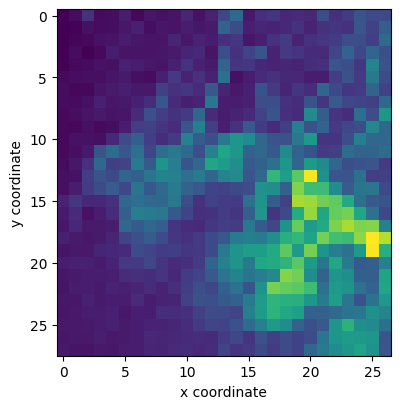

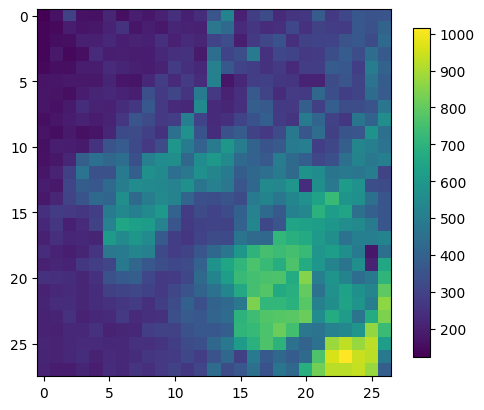

X.shape = (756, 2000)
X_mean.shape = (756, 2000)
eigenvalues.shape = (756,)
eigenvectors.shape = (756, 756)


/var/folders/vl/vg6mv9s130bg0cgfw0qnnhzm0000gn/T/ipykernel_10579/1574216260.py:99: RuntimeWarning: divide by zero encountered in divide
  distance = np.sum(np.square(y_model_fit[mask]-hist_eigvals_data[mask])/hist_eigvals_data[mask]) / len(nonzero_rho)


best_sigma_scale = 0.9
len(nonzero_rho) = 41
mask = [False  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False]


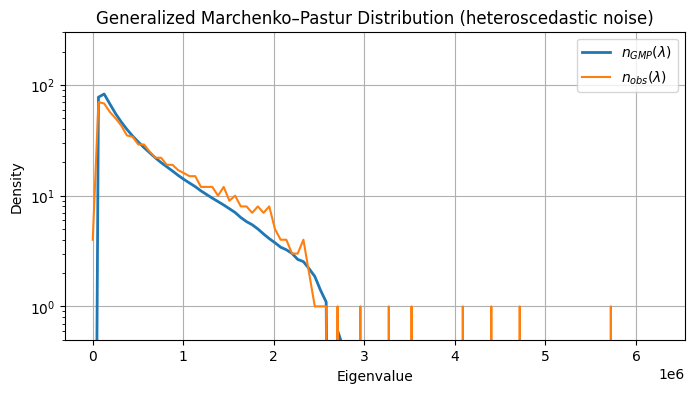

lambda_max_bulk_fit = 2767049.75
estimate_rank_signal = 15
eigenvalues.shape = (2000,)
eigenvectors.shape = (2000, 2000)
[[ 2.01671571e-03  1.37732015e-03  1.45436544e-03 ...  4.96152148e-04
  -2.22162809e-04 -7.80399569e-05]
 [ 1.37732015e-03  1.36703625e-03  1.07916293e-03 ...  5.35086554e-04
  -8.70555741e-05  1.06775966e-04]
 [ 1.45436544e-03  1.07916293e-03  1.75380264e-03 ...  4.39112366e-04
  -3.02641914e-04  1.49013131e-05]
 ...
 [ 4.96152148e-04  5.35086554e-04  4.39112366e-04 ...  1.26413140e-03
   3.04613059e-04  3.15013021e-04]
 [-2.22162809e-04 -8.70555741e-05 -3.02641914e-04 ...  3.04613059e-04
   1.42671657e-03  8.21873604e-04]
 [-7.80399569e-05  1.06775966e-04  1.49013131e-05 ...  3.15013021e-04
   8.21873604e-04  8.61955981e-04]]
[[ 4.7498936e-05  2.1600228e-05  2.3008572e-05 ... -3.2536827e-05
  -8.7051681e-05  1.0965133e-04]
 [ 2.1600228e-05  8.5701053e-05 -5.3305059e-05 ... -2.6006973e-04
  -1.1453625e-04  1.2311494e-04]
 [ 2.3008572e-05 -5.3305059e-05  5.2371447e-0

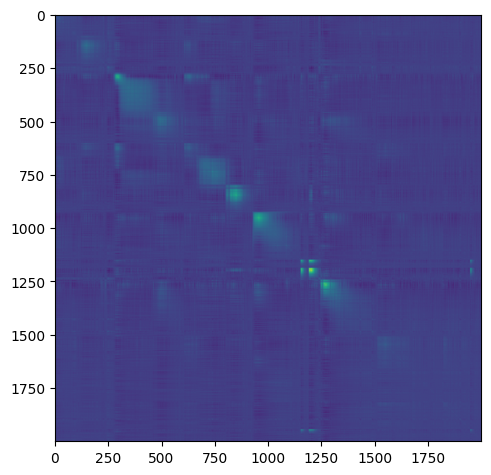

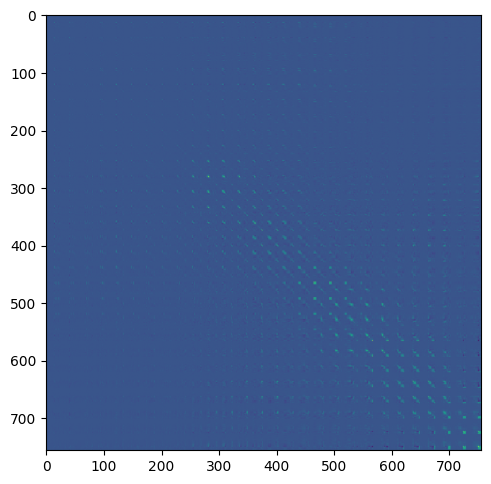

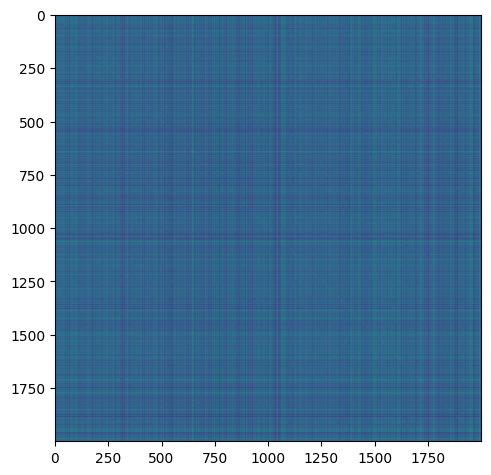

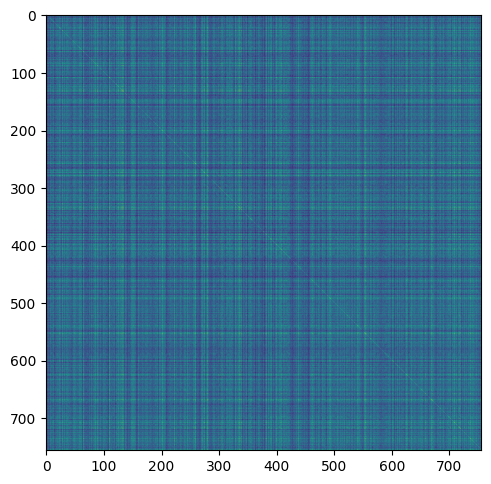

  0%|          | 0/10000 [00:00<?, ?it/s]

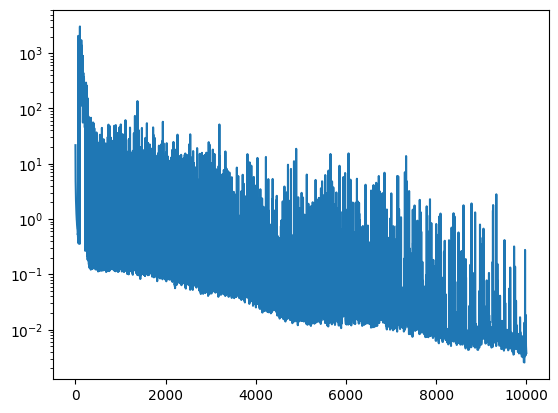

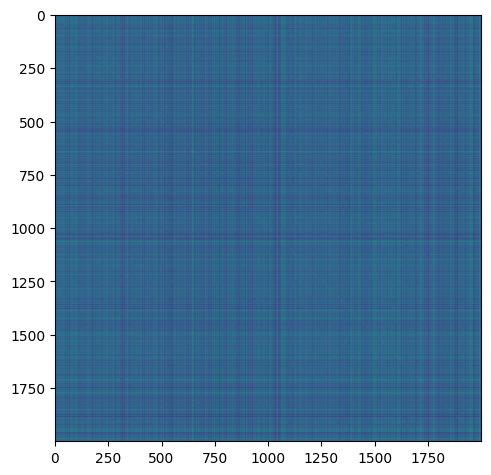

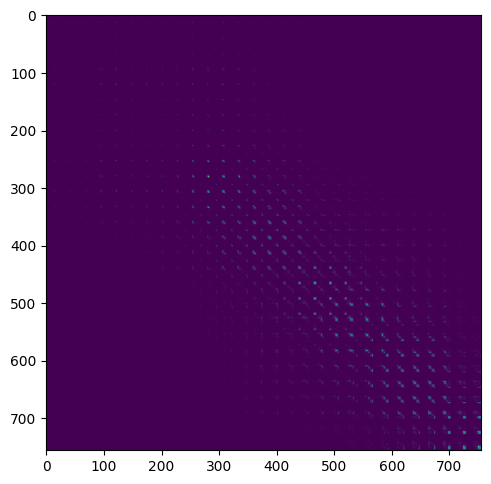

M_cossim.shape = (15, 15)
row_indices = [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
col_indices = [ 1  3  8  9  4  2  6 14  7  0 10 11 12 13  5]


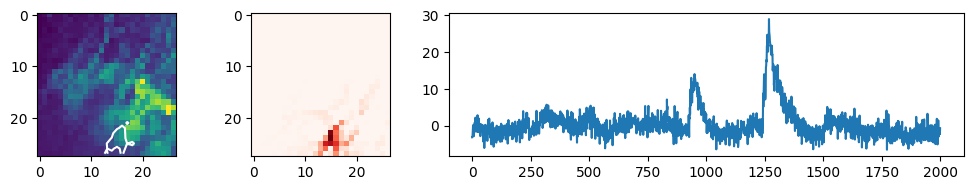

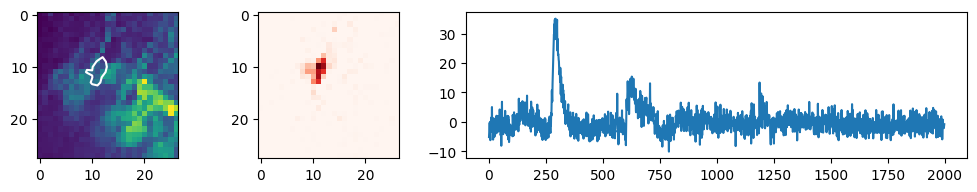

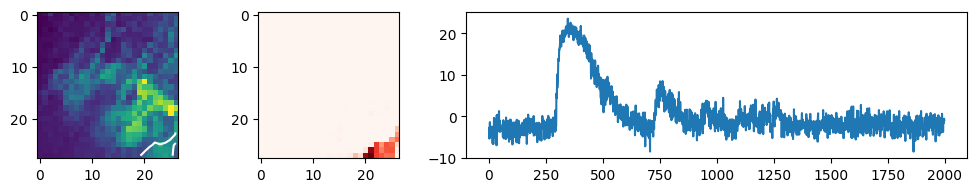

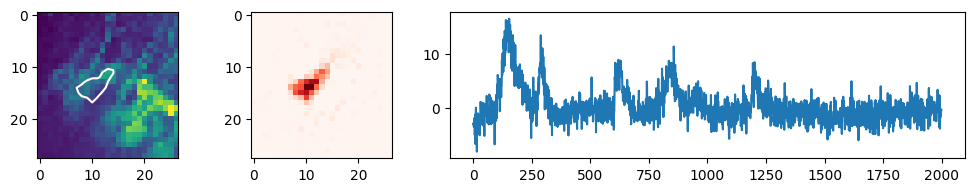

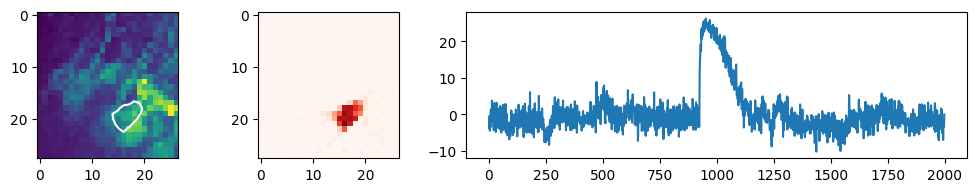

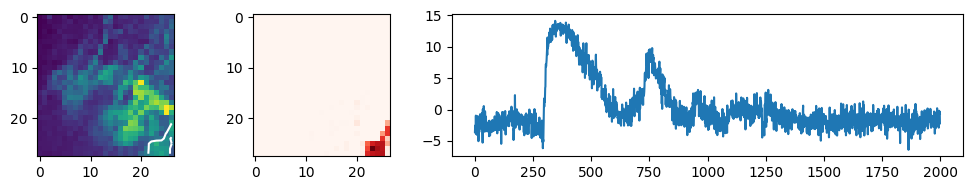

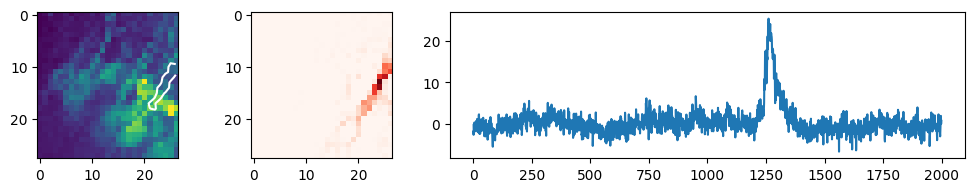

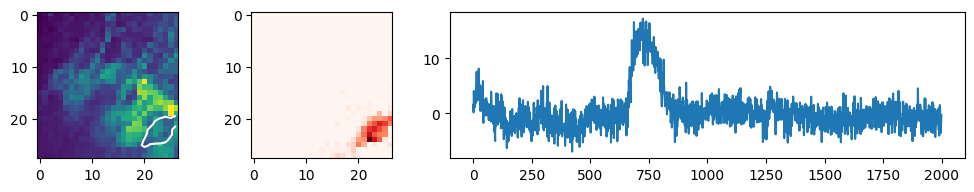

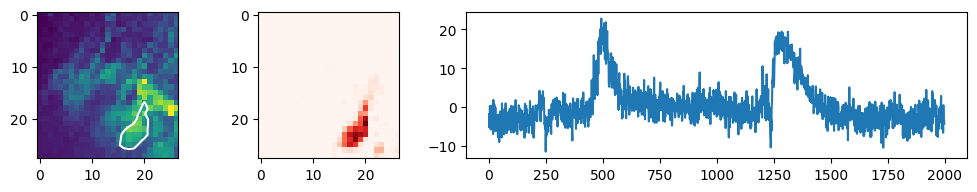

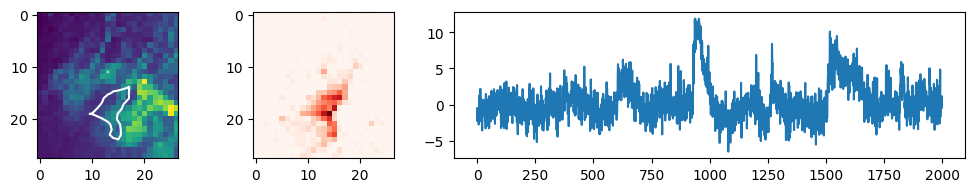

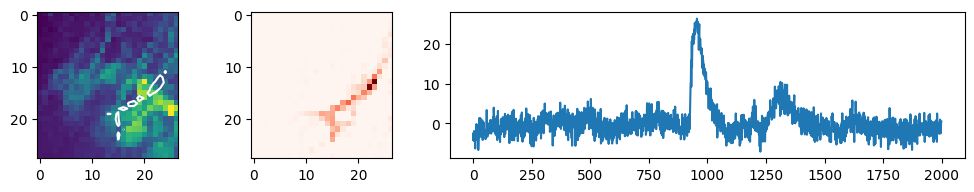

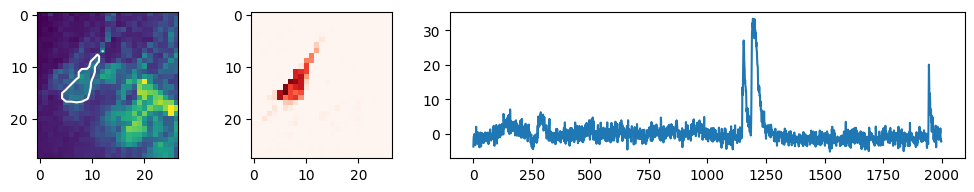

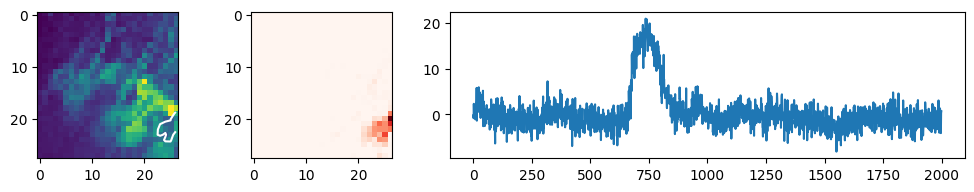

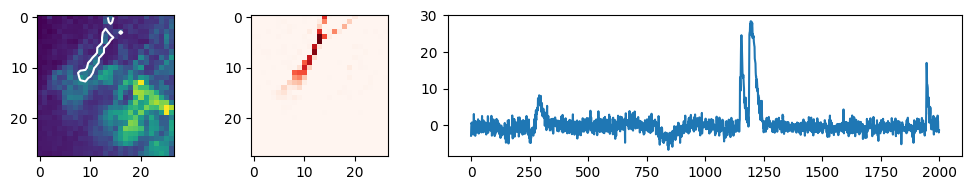

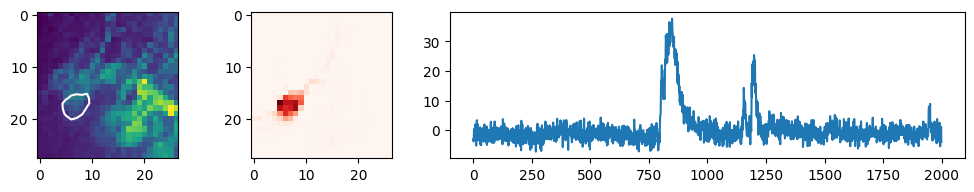

In [24]:
for fp, fl in zip(filepath,file_label):

    path = fp
    print (f"path = {path}")
    
    fig_label = fl + ana_label
    print (f"fig_label = {fig_label}")
    
    if "ToySim" in path:
        movie, N_movie, traces_truth, source_footprints = read_sim_data_file(path)
        plot_image_from_movie(fig_label, movie, source_footprints)
        plot_truth_traces(fig_label, traces_truth)
        vectorizer, unvec, X, Xn = vectorization(movie, N_movie)
        Xs, Xb = background_subtraction(X)
        plot_image('source_image'+fig_label, unvec, Xs)
        P, Pb, Pn, Ps, Pc = make_lag_time_data(X, Xb, Xs, Xn)
        Pw, Pcw, Pnw = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, n_sources)
        Zc = make_concatenated_matrix(Pcw)
        H, W = nonnegative_similarity_matching(fig_label, Zc, n_sources)
    elif "Fermi" in path:
        movie, N_movie, pix_x_coord, pix_y_coord, sky_x_coord, sky_y_coord, time_intervals, mjd_intervals = read_fermi_data_file(path)
        plot_image_from_movie(fig_label, movie)
        vectorizer, unvec, X, Xn = vectorization(movie, N_movie)
        Cx, Cy = coordinate_vectorization(pix_x_coord, pix_y_coord)
        Xs, Xb = background_subtraction(X)
        plot_image('source_image'+fig_label, unvec, Xs)
        P, Pb, Pn, Ps, Pc = make_lag_time_data(X, Xb, Xs, Xn)
        Px, Py = make_lag_time_coordinate(Cx, Cy)
        Z0 = make_concatenated_matrix(P)
        Zn0 = make_concatenated_matrix(Pn)
        Zs0 = make_concatenated_matrix(Ps)
        Zx = make_concatenated_matrix(Px)
        Zy = make_concatenated_matrix(Py)
        estimate_rank_signal = signal_rank_estimate(fig_label, Z0, Zn0, Zx, Zy)
        Pw, Pcw, Pnw = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal)
        Zc = make_concatenated_matrix(Pcw)
        H, W = nonnegative_similarity_matching(fig_label, Zc, estimate_rank_signal)
    else:
        movie, N_movie, pix_x_coord, pix_y_coord = read_data_file(path)
        plot_image_from_movie(fig_label, movie)
        vectorizer, unvec, X, Xn = vectorization(movie, N_movie)
        Cx, Cy = coordinate_vectorization(pix_x_coord, pix_y_coord)
        Xs, Xb = background_subtraction(X)
        plot_image('source_image'+fig_label, unvec, Xs)
        P, Pb, Pn, Ps, Pc = make_lag_time_data(X, Xb, Xs, Xn)
        Px, Py = make_lag_time_coordinate(Cx, Cy)
        Z0 = make_concatenated_matrix(P)
        Zn0 = make_concatenated_matrix(Pn)
        Zs0 = make_concatenated_matrix(Ps)
        Zx = make_concatenated_matrix(Px)
        Zy = make_concatenated_matrix(Py)
        # estimate_rank_signal = signal_rank_estimate(fig_label, Z0, Zn0, Zx, Zy)
        estimate_rank_signal = generalized_mp_density_fit(X, Xn, 100)
        # estimate_rank_signal = 10
        Pw, Pcw, Pnw = data_whitening(P, Ps, Pn, Pc, estimate_rank_signal, estimate_rank_signal)
        Zc = make_concatenated_matrix(Pcw)
        H, W = nonnegative_similarity_matching(fig_label, Zc, estimate_rank_signal)
        image_array, A_solved, S_solved, Sn_solved = reconstruction(unvec, Zc, Zn0, H, W, X.shape[0], estimate_rank_signal)
        plot_reconstruction(fig_label, movie, image_array, A_solved, S_solved, Sn_solved, estimate_rank_signal)

        